In [ ]:
from google.colab.drive import mount
import numpy as np
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df=pd.read_csv("/content/drive/MyDrive/Un-normalized data/Assamese/Unnormal_dataset_Assamese.csv")
df.columns
# df = df.replace([' HS'],'HS')
# df=df.replace(['LLU'],'LU')
# df=df.replace([' LS'],'LS')
# #df=df.replace(['nan'],'LS')

df=df.replace(['H U'],'HU')
df=df.replace(['LsU'],'LU')
df=df.replace(['LH'],'LS')
df=df.replace(['LL'],'LU')
df=df.replace(['LL'],'LU')
df=df.replace(['HH'],'HS')
df=df.replace(['UL'],'LU')
df=df.replace(['SL'],'LS')
df=df.replace(['UH'],'HU')
df=df.replace(['SH'],'HS')
df=df.replace(['H̜̜̜̜S'],'HS')
df['Tone_Stress'].unique()

array(['LS', 'LU', 'HS', 'HU'], dtype=object)

In [ ]:
df.drop('syllable', inplace=True, axis=1)

In [ ]:
from sklearn.model_selection import train_test_split
X = df.iloc[:,:-1]
y =  df.iloc[: ,-1:]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
# np.any(np.isnan(X_train))
# X_train = X_train.fillna(X_train.mean())
# np.any(np.isnan(X_train))
# df

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()
df.isnull().any().any()

False

USING DECISION TREE

In [ ]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
dt = DecisionTreeClassifier( max_depth=3, random_state=7)
dt.fit(X_train,y_train)
y_pred2= dt.predict(X_test)
acc1 = accuracy_score(y_test,y_pred2)*100
p=precision_score(y_test,y_pred2, average='micro')
recall = recall_score(y_test,y_pred2, average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc1)
F1_score=f1_score(y_test,y_pred2,average='micro')
print('F1 Score: ',F1_score)
#None, 'micro', 'macro', 'weighted'

Precision:  0.5596868884540117
Recall:  0.5596868884540117
Accuracy:  55.96868884540117
F1 Score:  0.5596868884540117


CONFUSION MATRIX FOR DECISION TREE

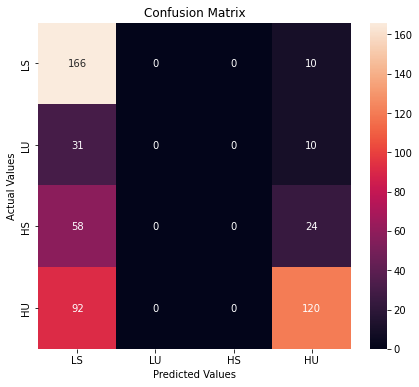

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, y_pred2)
cm_df = pd.DataFrame(cm,index = ['LS', 'LU', 'HS', 'HU'],columns = ['LS', 'LU', 'HS', 'HU'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

DECISION TREE K-CROSS VALIDATION

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
#dt = DecisionTreeClassifier( max_depth=3, random_state=7)

rf =DecisionTreeClassifier( max_depth=3, random_state=7)
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))


Cross-validation scores:[0.58577406 0.52719665 0.52521008 0.54621849 0.53781513]


USING GAUSSIAN NAIVE BAYES

In [ ]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import f1_score
model = GaussianNB()

model.fit(X_train,y_train)
pred = model.predict(X_test)
# print(pred)
from sklearn.metrics import accuracy_score
acc2 = accuracy_score(y_test,pred)*100
p=precision_score(y_test,pred, average='micro')
recall = recall_score(y_test,pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc2)
F1_score=f1_score(y_test,pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.14481409001956946
Recall:  0.14481409001956946
Accuracy:  14.481409001956946
F1 Score:  0.14481409001956946


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


CONFUSION MATRIX FOR NAIVE BAYES

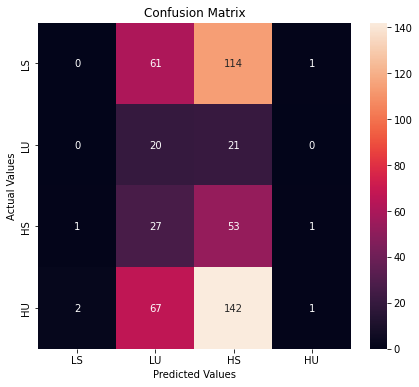

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, pred)
cm_df = pd.DataFrame(cm,index = ['LS', 'LU', 'HS', 'HU'],columns = ['LS', 'LU', 'HS', 'HU'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

GAUSSIAN NAIVE BAYES K-CROSS VALIDATION

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score

rf =GaussianNB()
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))


Cross-validation scores:[0.35564854 0.25523013 0.1512605  0.15546218 0.15546218]


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example usin

USING LOGISTIC REGRESSION

In [ ]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
model = LogisticRegression(solver = 'newton-cg',multi_class='auto',max_iter=1000)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
from sklearn.metrics import accuracy_score
acc3 = accuracy_score(y_test,y_pred)*100
p=precision_score(y_test,y_pred, average='micro')
recall = recall_score(y_test,y_pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc3)
F1_score=f1_score(y_test,y_pred,average='micro')
print('F1 Score: ',F1_score)

/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Precision:  0.49902152641878667
Recall:  0.49902152641878667
Accuracy:  49.902152641878665
F1 Score:  0.49902152641878667


/usr/local/lib/python3.7/dist-packages/sklearn/utils/optimize.py:212: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  ConvergenceWarning,


CONFUSION MATRIX FOR LOGISTIC REGRESSION

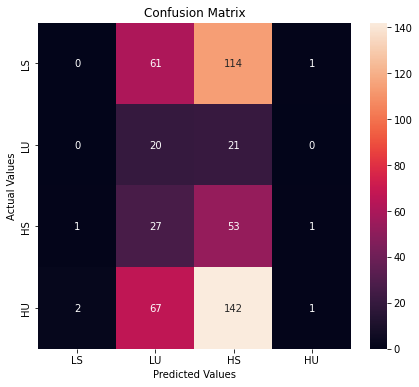

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, y_pred)
#cm_df = pd.DataFrame(cm,index = ['LS', 'LU', 'HS', 'HU'],columns = ['LS', 'LU', 'HS', 'HU'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

LOGISTIC REGRESSION K-CROSS VALIDATION

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression


rf =LogisticRegression(solver = 'newton-cg',multi_class='auto',max_iter=1000)
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/optimize.py:212: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  ConvergenceWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/scipy/optimize/linesearch.py:466: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/usr/local/lib/python3.7/dist-packages/scipy/optimize/linesearch.py:314: LineSearchWarning: Th

Cross-validation scores:[0.51046025 0.53138075 0.55462185 0.52521008 0.53361345]


/usr/local/lib/python3.7/dist-packages/sklearn/utils/optimize.py:212: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  ConvergenceWarning,


LOGISTIC REGRESSION WITH PIPE LINE

In [ ]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=100000,solver='lbfgs'))
pipe.fit(X_train, y_train)  # apply scaling on train
pred=pipe.predict(X_test)
# print(pred)
pipe.score(X_test, y_test)
acc4=accuracy_score(y_test,pred)*100
p=precision_score(y_test,pred, average='micro')
recall = recall_score(y_test,pred,average='micro')

print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc4)
F1_score=f1_score(y_test,pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.5117370892018779
Recall:  0.5117370892018779
Accuracy:  51.173708920187785
F1 Score:  0.5117370892018779


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [ ]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt


x_data = df.drop(['Tone_Stress'],axis=1)
y_data = df['Tone_Stress']
#DATA SCALING
# RobustScaler = preprocessing.RobustScaler()
StandardScaler = preprocessing.StandardScaler()
X_data_robust = StandardScaler.fit_transform(x_data)
data = pd.DataFrame(X_data_robust,columns=['F1', 'F2', 'F3', 'F4', 'F5','intensityMin', 'intensityMax', 'intensityAvg','intensityStdev ', 'intensityRange', ' duration','maxF0_Hz', 'minF0_Hz', 'meanF0_Hz','f0Range_Hz'])
data.head()

,F1,F2,F3,F4,F5,intensityMin,intensityMax,intensityAvg,intensityStdev,intensityRange,duration,maxF0_Hz,minF0_Hz,meanF0_Hz,f0Range_Hz
0,-0.631646,-0.625957,-0.669290,-0.676049,-0.689091,-0.072339,-0.006223,-0.127417,0.358797,-0.024224,0.775859,-0.335551,0.813644,0.897486,0.847752
1,-0.631656,-0.633014,-0.674212,-0.676716,-0.687191,-0.397496,0.218701,0.120937,0.272416,-0.024231,0.426017,0.326354,0.557622,0.824391,0.389692
2,-0.631676,-0.650473,-0.682866,-0.683654,-0.689601,-0.397496,-0.335789,0.055232,-0.535767,-0.024242,0.737094,1.174299,1.270838,1.127787,0.742125
3,-0.631859,-0.629465,-0.668043,-0.677643,-0.689968,0.485299,0.115629,-0.488424,1.294490,-0.024226,0.593582,0.473579,0.482272,0.977254,0.630745
4,-0.631980,-0.638879,-0.673224,-0.682409,-0.701015,-0.111654,-0.296678,-0.428756,-0.533046,-0.024231,-0.154527,1.071597,0.739159,0.667542,0.848031


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
X_train, X_test, y_train, y_test = train_test_split(data, y_data,test_size=0.2, random_state = 1)
knn_clf=LogisticRegression()
knn_clf.fit(X_train,y_train)
ypred=knn_clf.predict(X_test)

result = confusion_matrix(y_test, ypred)
print("Confusion Matrix:")
print(result)
result1 = classification_report(y_test, ypred)
print("Classification Report:")
print (result1)
result2= accuracy_score(y_test,ypred)
acc5=result2*100

p=precision_score(y_test,ypred, average='micro')
recall = recall_score(y_test,ypred,average='micro')

print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc5)
F1_score=f1_score(y_test,ypred,average='micro')
print('F1 Score: ',F1_score)

Confusion Matrix:
[[ 64   0   2  40]
 [ 15   0   0  15]
 [ 19   0   1  44]
 [ 28   0   1 112]]
Classification Report:
              precision    recall  f1-score   support

          HS       0.51      0.60      0.55       106
          HU       0.00      0.00      0.00        30
          LS       0.25      0.02      0.03        64
          LU       0.53      0.79      0.64       141

    accuracy                           0.52       341
   macro avg       0.32      0.35      0.30       341
weighted avg       0.42      0.52      0.44       341

Precision:  0.5190615835777126
Recall:  0.5190615835777126
Accuracy:  51.90615835777126
F1 Score:  0.5190615835777126


/usr/local/lib/python3.7/dist-packages/sklearn/linear_model/_logistic.py:818: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  extra_warning_msg=_LOGISTIC_SOLVER_CONVERGENCE_MSG,
/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0

CONFUSION MATRIX FOR LOGISTIC REGRESSION WITH PIPE LINE

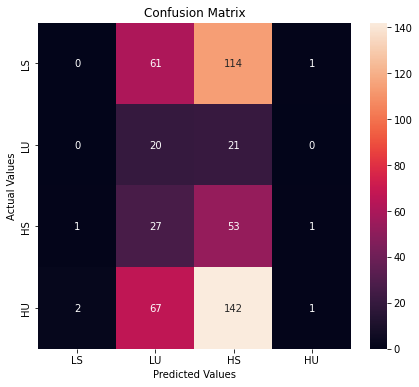

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, ypred)
#cm_df = pd.DataFrame(cm,index = ['LS', 'LU', 'HS', 'HU'],columns = ['LS', 'LU', 'HS', 'HU'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

LOGISTIC REGRESSION WITH PIPE LINE K-CROSS VALIDATION

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


rf =make_pipeline(StandardScaler(), LogisticRegression(max_iter=100000,solver='lbfgs'))
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))


Cross-validation scores:[0.53846154 0.5018315  0.55514706 0.55147059 0.54779412]


KNN

In [ ]:

from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt


x_data = df.drop(['Tone_Stress'],axis=1)
y_data = df['Tone_Stress']
#DATA SCALING
# RobustScaler = preprocessing.RobustScaler()
MinMaxScaler = preprocessing.MinMaxScaler()
X_data_robust = MinMaxScaler.fit_transform(x_data)
data = pd.DataFrame(X_data_robust,columns=['F1', 'F2', 'F3', 'F4', 'F5','intensityMin', 'intensityMax', 'intensityAvg','intensityStdev ', 'intensityRange', ' duration','maxF0_Hz', 'minF0_Hz', 'meanF0_Hz','f0Range_Hz'])
data.head()


,F1,F2,F3,F4,F5,intensityMin,intensityMax,intensityAvg,intensityStdev,intensityRange,duration,maxF0_Hz,minF0_Hz,meanF0_Hz,f0Range_Hz
0,0.000098,0.009939,0.009628,0.005895,0.017173,0.196174,0.038003,0.013713,0.084610,1.272197e-06,0.336441,0.255794,0.703372,0.835001,0.926428
1,0.000096,0.008037,0.007788,0.005654,0.017909,0.158425,0.045241,0.020514,0.081754,1.121917e-06,0.277010,0.394890,0.626666,0.809986,0.743688
2,0.000092,0.003332,0.004555,0.003146,0.016976,0.158425,0.027398,0.018715,0.055034,8.479936e-07,0.329856,0.573082,0.840352,0.913814,0.884289
3,0.000053,0.008994,0.010093,0.005319,0.016834,0.260911,0.041924,0.003828,0.115546,1.239898e-06,0.305476,0.425829,0.604090,0.862299,0.839855
4,0.000027,0.006457,0.008157,0.003596,0.012557,0.191609,0.028657,0.005461,0.055124,1.104505e-06,0.178387,0.551499,0.681056,0.756310,0.926540


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
X_train, X_test, y_train, y_test = train_test_split(data, y_data,test_size=0.2, random_state = 1)
knn_clf=KNeighborsClassifier()
knn_clf.fit(X_train,y_train)
ypred=knn_clf.predict(X_test)

result = confusion_matrix(y_test, ypred)
print("Confusion Matrix:")
print(result)
result1 = classification_report(y_test, ypred)
print("Classification Report:")
print (result1)
result2= accuracy_score(y_test,ypred)
acc5=result2*100

p=precision_score(y_test,ypred, average='micro')
recall = recall_score(y_test,ypred,average='micro')

print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc5)
F1_score=f1_score(y_test,ypred,average='micro')
print('F1 Score: ',F1_score)

Confusion Matrix:
[[56  7 14 29]
 [14  2  5  9]
 [25  3  3 33]
 [45  6  8 82]]
Classification Report:
              precision    recall  f1-score   support

          HS       0.40      0.53      0.46       106
          HU       0.11      0.07      0.08        30
          LS       0.10      0.05      0.06        64
          LU       0.54      0.58      0.56       141

    accuracy                           0.42       341
   macro avg       0.29      0.31      0.29       341
weighted avg       0.37      0.42      0.39       341

Precision:  0.41935483870967744
Recall:  0.41935483870967744
Accuracy:  41.935483870967744
F1 Score:  0.41935483870967744


CONFUSION MATRIX FOR KNN

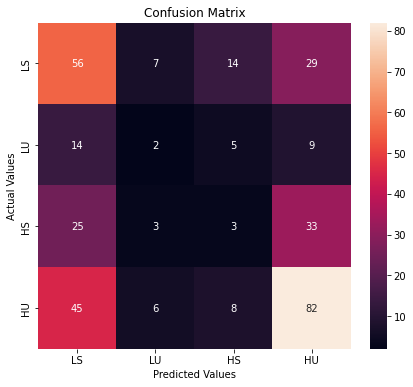

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, ypred)
cm_df = pd.DataFrame(cm,index = ['LS', 'LU', 'HS', 'HU'],columns = ['LS', 'LU', 'HS', 'HU'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

KNN K-CROSS VALIDATION

In [ ]:
#from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

rf =KNeighborsClassifier()
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))

Cross-validation scores:[0.47252747 0.42857143 0.43382353 0.41544118 0.41544118]


SUPPORT VECTOR MACHINE

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
svc1 = SVC(C=1,kernel='rbf',gamma=1,max_iter=10000,random_state=101)     
svc1.fit(X_train,y_train)
y_pred = svc1.predict(X_test)
from sklearn.metrics import accuracy_score
acc6= accuracy_score(y_test,y_pred)*100
acc6

#p=precision_score(y_test,pred, average='micro')
#recall = recall_score(y_test,pred,average='micro')
p=precision_score(y_test,y_pred, average='micro')
recall = recall_score(y_test,y_pred,average='micro') 
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc6)
F1_score=f1_score(y_test,y_pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.49853372434017595
Recall:  0.49853372434017595
Accuracy:  49.853372434017594
F1 Score:  0.49853372434017595


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
X_train, X_test, y_train, y_test = train_test_split(data, y_data,test_size=0.2, random_state = 1)
knn_clf=KNeighborsClassifier()
knn_clf.fit(X_train,y_train)
ypred=knn_clf.predict(X_test)

result = confusion_matrix(y_test, ypred)
print("Confusion Matrix:")
print(result)
result1 = classification_report(y_test, ypred)
print("Classification Report:")
print (result1)
result2= accuracy_score(y_test,ypred)
acc5=result2*100
print("Accuracy:",acc5)

Confusion Matrix:
[[56  7 14 29]
 [14  2  5  9]
 [25  3  3 33]
 [45  6  8 82]]
Classification Report:
              precision    recall  f1-score   support

          HS       0.40      0.53      0.46       106
          HU       0.11      0.07      0.08        30
          LS       0.10      0.05      0.06        64
          LU       0.54      0.58      0.56       141

    accuracy                           0.42       341
   macro avg       0.29      0.31      0.29       341
weighted avg       0.37      0.42      0.39       341

Accuracy: 41.935483870967744


CONFUSION MATRIX FOR SVM

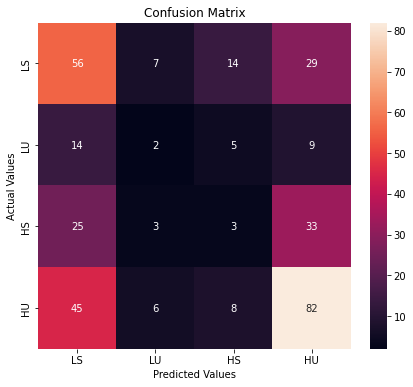

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, y_pred)
#cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

SVM K-CROSS VALIDATION

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

rf =SVC(C=1,kernel='rbf',gamma=1,max_iter=10000,random_state=101)
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))

Cross-validation scores:[0.51282051 0.49084249 0.5        0.52205882 0.49632353]


ENSEMBLE LEARNING

In [ ]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
bagging = BaggingClassifier(RandomForestClassifier(n_estimators = 200, criterion = 'entropy', random_state =42,max_depth=15),max_samples=0.5, max_features=0.5)
bagging.fit(X_train, y_train)
pred=bagging.predict(X_test)
p=precision_score(y_test,pred, average='micro')
recall = recall_score(y_test,pred,average='micro')
 
print('Precision: ',p)
print('Recall: ',recall)
acc7=accuracy_score(y_test,pred)*100
print('Accuracy: ',acc7)
F1_score=f1_score(y_test,pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.6187683284457478
Recall:  0.6187683284457478
Accuracy:  61.87683284457478
F1 Score:  0.6187683284457478


CONFUSION MATRIX FOR ENSEMBLE LEARNING

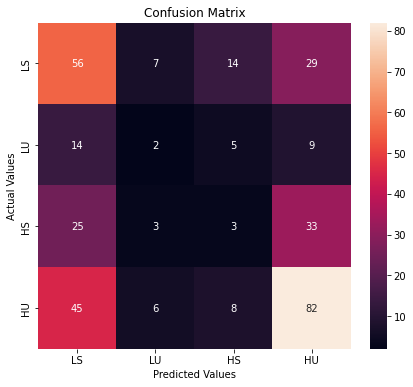

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, pred)
#cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')

plt.show()

ENSEMBLE LEARNING K-CROSS VALIDATION

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf = BaggingClassifier(RandomForestClassifier(n_estimators = 200, criterion = 'entropy', random_state =42,max_depth=15),max_samples=0.5, max_features=0.5)   
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))

Cross-validation scores:[0.58241758 0.62637363 0.60661765 0.60294118 0.58088235]


RANDOM FOREST

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
# from sklearn.externals import joblib
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

classifier = RandomForestClassifier(n_estimators = 200, criterion = 'entropy', random_state =42,max_depth=15)
classifier.fit(X_train, y_train)



# Predicting the Test set results
y_pred = classifier.predict(X_test)
p=precision_score(y_test,y_pred, average='micro')
recall = recall_score(y_test,y_pred,average='micro')
F1_score=f1_score(y_test, y_pred, average='micro')
acc8=accuracy_score(y_test,y_pred)*100
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc8)
F1_score=f1_score(y_test,y_pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.6011730205278593
Recall:  0.6011730205278593
Accuracy:  60.117302052785924
F1 Score:  0.6011730205278593


CONFUSION MATRIX FOR RANDOM FOREST

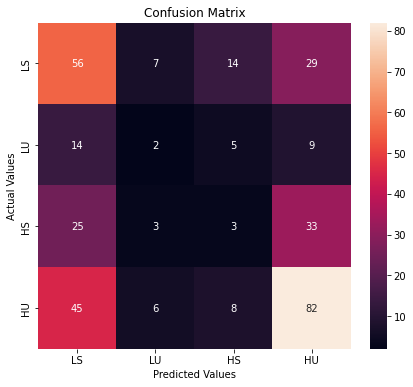

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, y_pred)
#cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

RANDOM FOREST K-CROSS VALIDATION

In [ ]:
#from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100,random_state=1, n_jobs=-1)    
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    
from sklearn.model_selection import cross_val_score
scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))

Cross-validation scores:[0.6043956  0.63369963 0.61397059 0.59926471 0.59191176]


Chart

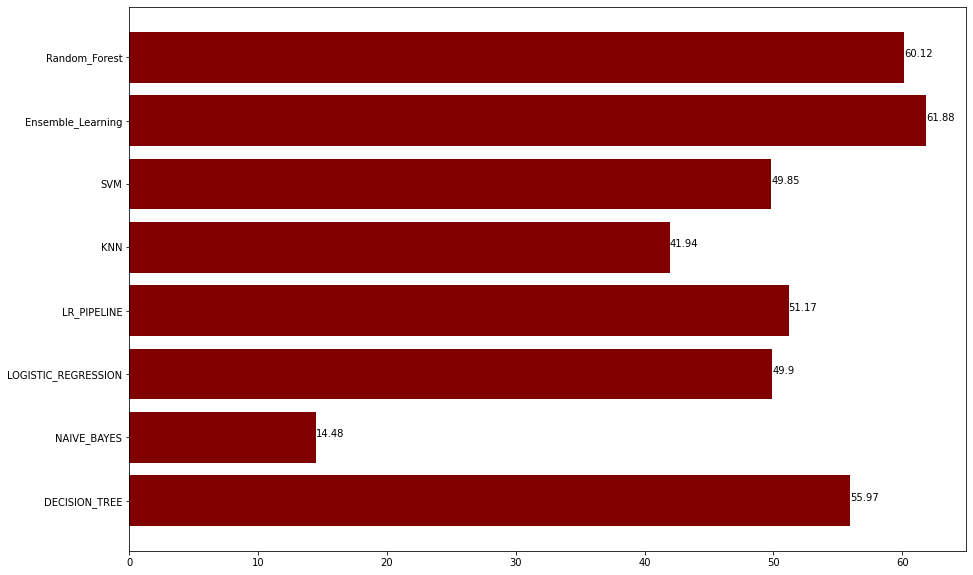

In [ ]:
import matplotlib.pyplot as plt
Model = ["DECISION_TREE",  "NAIVE_BAYES", "LOGISTIC_REGRESSION","LR_PIPELINE","KNN","SVM","Ensemble_Learning","Random_Forest"]
#acc = [round(acc1,2),round(acc2,2), round(acc3,2),round(acc4,2),round(acc5,2),round(acc6,2),round(acc7,2),round(acc8,2)]
acc = [round(acc1,2),round(acc2,2), round(acc3,2),round(acc4,2),round(acc5,2),round(acc6,2),round(acc7,2),round(acc8,2)]
fig = plt.figure(figsize = (15,10 ))
plt.barh(Model,acc,color="maroon")
for index, value in enumerate(acc):
  plt.text(value, index,str(value))
plt.show()  